# 02 - EDA: logistics time series
Targets: `delivery_time_deviation`, `delay_probability`, `risk_classification`.
Key question: do the sensor / traffic / weather columns actually carry signal about these targets?

In [1]:
import sys; sys.path.append("..")
import yaml, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src.data.load import load_logistics
from src.data.clean import clean_logistics

cfg = yaml.safe_load(open("../config.yaml"))
raw = load_logistics("../" + cfg["paths"]["logistics"])
df = clean_logistics(raw)
print(raw.shape, "->", df.shape)
df.head()

(32065, 26) -> (32065, 26)


,timestamp,vehicle_gps_latitude,vehicle_gps_longitude,fuel_consumption_rate,eta_variation_hours,traffic_congestion_level,warehouse_inventory_level,loading_unloading_time,handling_equipment_availability,order_fulfillment_status,...,iot_temperature,cargo_condition_status,route_risk_level,customs_clearance_time,driver_behavior_score,fatigue_monitoring_score,disruption_likelihood_score,delay_probability,risk_classification,delivery_time_deviation
0,2021-01-01 00:00:00,40.375568,-77.014318,5.136512,4.998009,5.927586,985.716862,4.951392,0.481294,0.761166,...,0.574400,0.777263,1.182116,0.502006,0.033843,0.978599,0.506152,0.885291,Moderate Risk,9.110682
1,2021-01-01 01:00:00,33.507818,-117.036902,5.101512,0.984929,1.591992,396.700206,1.030379,0.620780,0.196594,...,-9.753493,0.091839,9.611988,0.966774,0.201725,0.918586,0.980784,0.544178,High Risk,8.175281
2,2021-01-01 02:00:00,30.020640,-75.269224,5.090803,4.972665,8.787765,832.408935,4.220229,0.810933,0.152742,...,-6.491034,0.253529,6.570431,0.945627,0.264045,0.394215,0.998633,0.803322,High Risk,1.283594
3,2021-01-01 03:00:00,36.649223,-70.190529,8.219558,3.095064,0.045257,0.573283,0.530186,0.008525,0.811885,...,-0.151276,0.877576,0.548952,4.674035,0.362885,0.905444,0.993320,0.025977,High Risk,9.304897
4,2021-01-01 04:00:00,30.001279,-70.012195,5.000075,3.216077,8.004851,914.925067,3.620890,0.020083,0.053659,...,2.429448,0.262081,8.861443,3.445429,0.016957,0.258702,0.912433,0.991122,High Risk,7.752484


## 1. Data audit

In [2]:

print("Date range:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Step between rows:", df["timestamp"].diff().value_counts().head(3).to_dict())
print("Duplicates:", raw.duplicated().sum(), "| missing cells:", int(raw.isna().sum().sum()))
df.describe().T.round(2)

Date range: 2021-01-01 00:00:00 -> 2024-08-29 00:00:00
Step between rows: {Timedelta('0 days 01:00:00'): 32064}
Duplicates: 0 | missing cells: 0


,count,mean,min,25%,50%,75%,max,std
timestamp,32065,2022-10-31 00:00:00.000000256,2021-01-01 00:00:00,2021-12-01 00:00:00,2022-10-31 00:00:00,2023-09-30 00:00:00,2024-08-29 00:00:00,NaN
vehicle_gps_latitude,32065.0,38.023589,30.0,31.28055,36.41382,44.453655,50.0,6.917909
vehicle_gps_longitude,32065.0,-90.116648,-119.999998,-106.253913,-86.293414,-73.079367,-70.0,17.369244
fuel_consumption_rate,32065.0,8.011735,5.0,5.019984,5.636036,9.669944,19.999875,4.26496
eta_variation_hours,32065.0,2.893068,-1.999993,1.185744,3.882059,4.884355,5.0,2.274044
traffic_congestion_level,32065.0,4.991493,0.0,1.47472,4.981244,8.534902,9.999999,3.532048
warehouse_inventory_level,32065.0,299.254732,0.0,16.051635,157.288022,540.597991,999.999298,323.443513
loading_unloading_time,32065.0,2.291669,0.5,0.774798,1.917121,3.734188,5.0,1.554202
handling_equipment_availability,32065.0,0.302695,0.0,0.017108,0.159515,0.553595,0.999999,0.325915
order_fulfillment_status,32065.0,0.60074,0.000001,0.277096,0.680553,0.93816,1.0,0.345672


## 2. Targets

risk_classification
High Risk        0.747
Moderate Risk    0.156
Low Risk         0.097
Name: proportion, dtype: float64


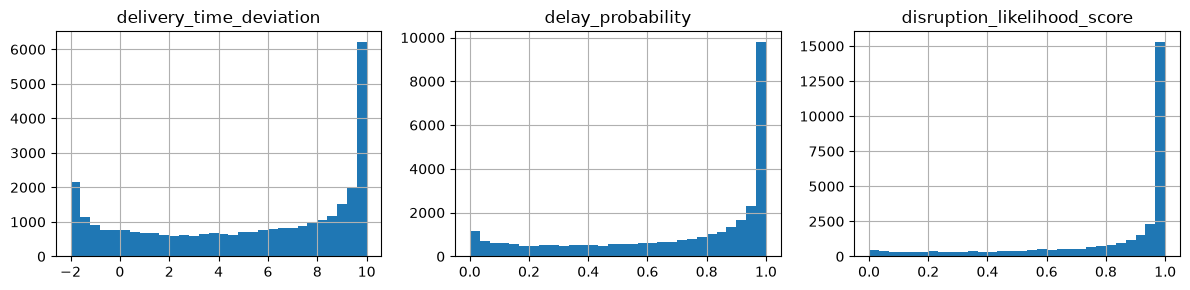

In [3]:
print(df["risk_classification"].value_counts(normalize=True).round(3))
targets = ["delivery_time_deviation", "delay_probability", "disruption_likelihood_score"]
df[targets].hist(bins=30, figsize=(12, 3), layout=(1, 3)); plt.tight_layout(); plt.show()


## 3. How is `risk_classification` built?
If it is just a binned version of `disruption_likelihood_score`, then using that score as a feature is pure leakage.

In [4]:






print(df.groupby("risk_classification")["disruption_likelihood_score"].agg(["min", "max", "mean"]).round(3))
rule = pd.cut(df["disruption_likelihood_score"], [-np.inf, 0.3, 0.7, np.inf],
              labels=["Low Risk", "Moderate Risk", "High Risk"], right=False)
print("Agreement with rule (<0.3 Low, <0.7 Moderate, else High):",
      (rule.astype(str) == df["risk_classification"]).mean().round(4))

                     min  max   mean
risk_classification                 
High Risk            0.7  1.0  0.949
Low Risk             0.0  0.3  0.143
Moderate Risk        0.3  0.7  0.519
Agreement with rule (<0.3 Low, <0.7 Moderate, else High): 1.0


## 4. Do any raw columns relate to the targets?

,delivery_time_deviation,delay_probability,disruption_likelihood_score
fuel_consumption_rate,0.012,0.014,0.002
port_congestion_level,0.011,0.009,0.005
customs_clearance_time,0.009,0.005,0.000
warehouse_inventory_level,0.007,0.005,0.014
handling_equipment_availability,0.005,0.003,0.004
supplier_reliability_score,0.004,0.002,0.002
driver_behavior_score,0.004,0.004,0.006
fatigue_monitoring_score,0.003,0.001,0.003
loading_unloading_time,0.003,0.001,0.003
order_fulfillment_status,0.003,0.010,0.008


Largest |correlation| between any raw feature and any target: 0.014


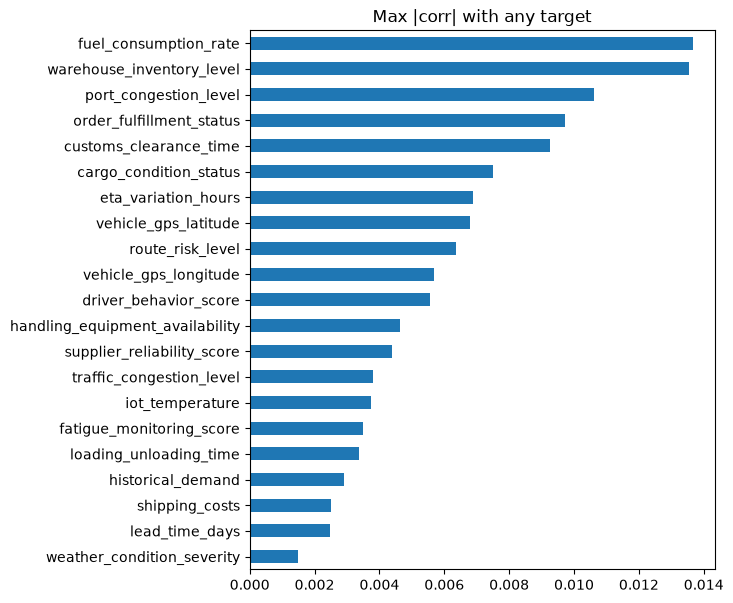

In [5]:
num = df.select_dtypes("number")
corr = num.corr()[targets].drop(targets).abs()
display(corr.sort_values("delivery_time_deviation", ascending=False).round(3).head(10))
print("Largest |correlation| between any raw feature and any target:", corr.values.max().round(3))
corr.max(axis=1).sort_values().plot.barh(figsize=(6, 7), title="Max |corr| with any target"); plt.show()

## 5. Is it behaving like a real time series?
Real traffic, weather and delay series are autocorrelated (this hour looks like last hour).

traffic_congestion_level       lag-1 autocorrelation: +0.003
weather_condition_severity     lag-1 autocorrelation: +0.001
port_congestion_level          lag-1 autocorrelation: +0.006
delivery_time_deviation        lag-1 autocorrelation: -0.012
delay_probability              lag-1 autocorrelation: +0.006


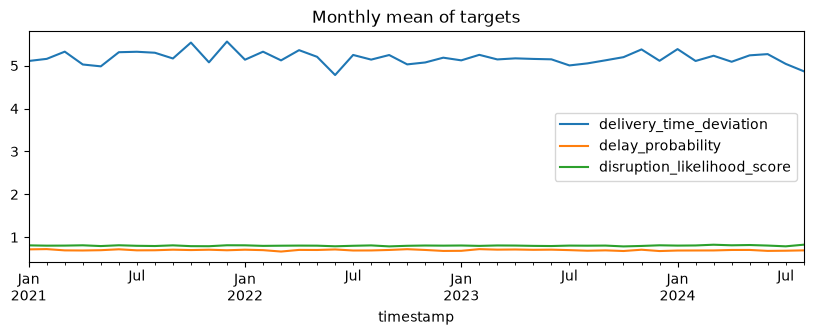

In [6]:
for c in ["traffic_congestion_level", "weather_condition_severity", "port_congestion_level",
          "delivery_time_deviation", "delay_probability"]:
    print(f"{c:30s} lag-1 autocorrelation: {df[c].autocorr(1):+.3f}")
df.set_index("timestamp")[targets].resample("ME").mean().plot(figsize=(10, 3), title="Monthly mean of targets"); plt.show()

## 6. Predictability smoke test (time-based split)
If a random forest cannot beat a constant guess here, boosted trees will not either.

In [7]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, accuracy_score, f1_score
from src.features.build_features import time_split, LOGISTICS_TARGETS

feats = [c for c in num.columns if c not in LOGISTICS_TARGETS + ["disruption_likelihood_score"]]
train, val, test = time_split(df)

print("Regression (R2 on the most recent 15%; 0 = no better than predicting the mean):")
for t in targets:
    m = RandomForestRegressor(100, min_samples_leaf=10, n_jobs=-1, random_state=cfg["seed"]).fit(train[feats], train[t])
    print(f"  {t:30s} R2 = {r2_score(test[t], m.predict(test[feats])):+.3f}")

print("\nRisk class (accuracy / macro-F1 on the most recent 15%):")
major = train["risk_classification"].mode()[0]
print(f"  always predict '{major}': acc = {(test['risk_classification'] == major).mean():.3f}")
for name, cols in [("raw features only", feats), ("+ disruption_likelihood_score", feats + ["disruption_likelihood_score"])]:
    m = RandomForestClassifier(100, min_samples_leaf=10, n_jobs=-1, random_state=cfg["seed"]).fit(train[cols], train["risk_classification"])
    p = m.predict(test[cols])
    print(f"  {name:32s} acc = {accuracy_score(test['risk_classification'], p):.3f}  macro-F1 = {f1_score(test['risk_classification'], p, average='macro'):.3f}")

Regression (R2 on the most recent 15%; 0 = no better than predicting the mean):
  delivery_time_deviation        R2 = -0.011
  delay_probability              R2 = -0.010
  disruption_likelihood_score    R2 = -0.012

Risk class (accuracy / macro-F1 on the most recent 15%):
  always predict 'High Risk': acc = 0.760
  raw features only                acc = 0.760  macro-F1 = 0.288
  + disruption_likelihood_score    acc = 1.000  macro-F1 = 1.000


## Findings (fill in)
1. 
2. 
3. 
4. 
5. 